In [1]:
# %% [markdown]
# # Identificar Variables Críticas para Análisis PISA
# 
# Este script te ayuda a identificar automáticamente qué variables
# son críticas para tu análisis basándose en:
# 1. Correlación con variables de outcome
# 2. Completitud de datos
# 3. Variabilidad
# 4. Importancia teórica

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar tu dataset
df = pd.read_csv('../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv')  # Ajusta el nombre

print(f"Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas")

C:\Users\max_a\AppData\Local\Temp\ipykernel_23132\4162741308.py:18: DtypeWarning: Columns (1324,1418,2214,2215,2221,2222,2228,2229,2230,2231,2237,2238,2251,2399,2405,2411,2412,2418,2419,2420,2421,2422,2435,2436,2442,2448,2449,2455,2456,2740,2746,2752,2753,2759,2760,2766,2772,2773,2779,2780,2786,2907,2908,2914,2920,2921,2927,2963,3033,3034,3040,3041,3047,3053,3054,3060,3066,3067,3073,3107,3108,3114,3126,3127,3133,3134,3135,3136,3137,3143,3149,3150,3156,3157,3163,3169,3170,3171,3172,3173,3174,3178,3179,3216,3222,3223,3279,3285,3286,3292,3293,3299,3300,3306,3307,3314,3315,3316,3317,3318,3324,3365,3371,3392,3393,3394,3395,3396,3397,3403,3429,3435,3441,3442,3454,3460,5083,7074,7075,7081,7082) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv')  # Ajusta el nombre


Dataset cargado: 6968 filas, 7147 columnas


In [2]:
# %% [markdown]
# ## 1. Identificar variables de RENDIMIENTO (outcomes)

# %%
# Buscar variables de rendimiento por patrón
patrones_rendimiento = ['PV1MATH', 'PV1READ', 'PV1SCIE', 'PV2MATH', 'PV2READ', 'PV2SCIE',
                        'MATH', 'READ', 'SCIE', 'SCORE']

variables_rendimiento = []
for patron in patrones_rendimiento:
    matches = [col for col in df.columns if patron in col.upper()]
    variables_rendimiento.extend(matches)

# Eliminar duplicados
variables_rendimiento = list(set(variables_rendimiento))

print("✓ Variables de RENDIMIENTO identificadas:")
for var in variables_rendimiento[:10]:  # Mostrar primeras 10
    print(f"  - {var}")

if len(variables_rendimiento) == 0:
    print("  ⚠️ No se encontraron variables de rendimiento automáticamente")
    print("  Define manualmente tu variable outcome principal")

✓ Variables de RENDIMIENTO identificadas:
  - PV9MATH
  - MATHEFF
  - PV4SCIE
  - PV7MATH
  - PV5READ
  - PV8READ
  - PV4MATH
  - MATHPERS
  - PV10SCIE
  - PV1SCIE


In [3]:
# %% [markdown]
# ## 2. Identificar variables SOCIOECONÓMICAS

# %%
# Patrones conocidos de variables socioeconómicas en PISA
patrones_nse = ['ESCS', 'HOMEPOS', 'WEALTH', 'CULTPOSS', 'HEDRES', 'HISEI']

variables_nse = []
for patron in patrones_nse:
    matches = [col for col in df.columns if patron in col.upper()]
    variables_nse.extend(matches)

variables_nse = list(set(variables_nse))

print("\n✓ Variables SOCIOECONÓMICAS identificadas:")
for var in variables_nse:
    print(f"  - {var}")

if len(variables_nse) == 0:
    print("  ⚠️ No se encontraron variables socioeconómicas automáticamente")


✓ Variables SOCIOECONÓMICAS identificadas:
  - HOMEPOS
  - ESCS
  - HISEI


In [4]:
# %% [markdown]
# ## 3. Identificar variables DEMOGRÁFICAS

# %%
patrones_demograficos = ['ST004D01T', 'GENDER', 'AGE', 'IMMIG', 'LANG']

variables_demograficas = []
for patron in patrones_demograficos:
    matches = [col for col in df.columns if patron in col.upper()]
    variables_demograficas.extend(matches)

variables_demograficas = list(set(variables_demograficas))

print("\n✓ Variables DEMOGRÁFICAS identificadas:")
for var in variables_demograficas:
    print(f"  - {var}")


✓ Variables DEMOGRÁFICAS identificadas:
  - LANGTEST_QQQ_stu
  - LANGTEST_QQQ_sch
  - ST004D01T
  - LANGTEST_COG
  - LANGTEST_PAQ
  - AGE
  - IMMIG
  - LANGN



VARIABLES MÁS CORRELACIONADAS CON: PV9MATH
  PV6MATH                                  r = 0.878
  PV8MATH                                  r = 0.876
  PV4MATC                                  r = 0.875
  PV1MATC                                  r = 0.875
  PV10MATC                                 r = 0.874
  PV7MATH                                  r = 0.873
  PV3MATC                                  r = 0.873
  PV8MATC                                  r = 0.872
  PV7MATC                                  r = 0.872
  PV4MATH                                  r = 0.872
  PV6MATC                                  r = 0.872
  PV3MATH                                  r = 0.872
  PV5MATH                                  r = 0.871
  PV2MATH                                  r = 0.870
  PV1MATH                                  r = 0.870


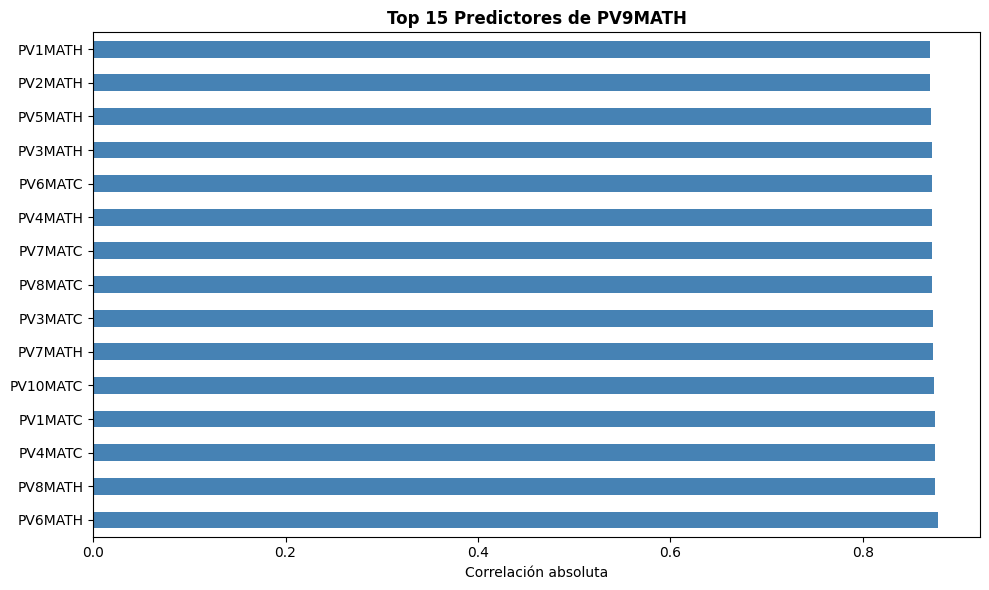

In [5]:
# %% [markdown]
# ## 4. Análisis de CORRELACIÓN con outcome

# %%
def encontrar_mejores_predictores(df, var_outcome, top_n=20):
    """
    Encuentra las variables más correlacionadas con el outcome
    """
    if var_outcome not in df.columns:
        print(f"⚠️ Variable {var_outcome} no encontrada")
        return None
    
    # Seleccionar solo variables numéricas
    df_numeric = df.select_dtypes(include=[np.number])
    
    # Calcular correlaciones
    correlaciones = df_numeric.corr()[var_outcome].abs().sort_values(ascending=False)
    
    # Excluir la variable misma y otras PV del mismo dominio
    correlaciones = correlaciones[correlaciones.index != var_outcome]
    
    # Filtrar valores muy bajos
    correlaciones = correlaciones[correlaciones > 0.05]
    
    return correlaciones.head(top_n)

# Analizar correlaciones si hay variables de rendimiento
if len(variables_rendimiento) > 0:
    outcome_principal = variables_rendimiento[0]  # Usar la primera
    
    print(f"\n{'='*70}")
    print(f"VARIABLES MÁS CORRELACIONADAS CON: {outcome_principal}")
    print(f"{'='*70}")
    
    top_correlaciones = encontrar_mejores_predictores(df, outcome_principal, top_n=15)
    
    if top_correlaciones is not None:
        for var, corr in top_correlaciones.items():
            print(f"  {var:40s} r = {corr:.3f}")
        
        # Visualización
        plt.figure(figsize=(10, 6))
        top_correlaciones.plot(kind='barh', color='steelblue')
        plt.xlabel('Correlación absoluta')
        plt.title(f'Top 15 Predictores de {outcome_principal}', fontweight='bold')
        plt.tight_layout()
        plt.show()

In [6]:
# %% [markdown]
# ## 5. Análisis de COMPLETITUD de datos

# %%
def analizar_completitud(df, variables):
    """
    Analiza qué tan completas están las variables
    """
    completitud = []
    
    for var in variables:
        if var in df.columns:
            n_total = len(df)
            n_missing = df[var].isna().sum()
            pct_completo = (1 - n_missing/n_total) * 100
            
            completitud.append({
                'Variable': var,
                'N_Completos': n_total - n_missing,
                'N_Missing': n_missing,
                'Pct_Completo': pct_completo
            })
    
    return pd.DataFrame(completitud).sort_values('Pct_Completo', ascending=False)

# Analizar todas las variables identificadas
todas_vars = list(set(variables_rendimiento + variables_nse + variables_demograficas))

if len(todas_vars) > 0:
    print(f"\n{'='*70}")
    print("ANÁLISIS DE COMPLETITUD DE DATOS")
    print(f"{'='*70}")
    
    df_completitud = analizar_completitud(df, todas_vars)
    print(df_completitud.to_string(index=False))
    
    # Alertas
    vars_incompletas = df_completitud[df_completitud['Pct_Completo'] < 90]
    if len(vars_incompletas) > 0:
        print(f"\n⚠️ {len(vars_incompletas)} variables con <90% de datos completos")
    else:
        print("\n✓ Todas las variables tienen >90% de datos completos")


ANÁLISIS DE COMPLETITUD DE DATOS
        Variable  N_Completos  N_Missing  Pct_Completo
         PV9MATH         6968          0    100.000000
         PV5READ         6968          0    100.000000
         PV4SCIE         6968          0    100.000000
         PV1MATH         6968          0    100.000000
         PV1READ         6968          0    100.000000
         PV7MATH         6968          0    100.000000
         PV8READ         6968          0    100.000000
         PV4MATH         6968          0    100.000000
        PV10SCIE         6968          0    100.000000
         PV1SCIE         6968          0    100.000000
         TOTMATH         6968          0    100.000000
         PV2READ         6968          0    100.000000
         PV5MATH         6968          0    100.000000
         ABGMATH         6968          0    100.000000
         PV2MATH         6968          0    100.000000
        PV10MATH         6968          0    100.000000
         PV9SCIE         6968  

In [7]:
# %% [markdown]
# ## 6. Análisis de VARIABILIDAD

# %%
def analizar_variabilidad(df, variables):
    """
    Analiza la variabilidad de las variables
    Variables sin variación no son útiles
    """
    variabilidad = []
    
    for var in variables:
        if var in df.columns:
            if df[var].dtype in ['float64', 'int64']:
                data = df[var].dropna()
                if len(data) > 0:
                    cv = data.std() / abs(data.mean()) if data.mean() != 0 else 0
                    variabilidad.append({
                        'Variable': var,
                        'DE': data.std(),
                        'CV': cv,
                        'Min': data.min(),
                        'Max': data.max(),
                        'Rango': data.max() - data.min()
                    })
            else:  # Categóricas
                n_categorias = df[var].nunique()
                variabilidad.append({
                    'Variable': var,
                    'N_Categorias': n_categorias,
                    'Tipo': 'Categórica'
                })
    
    return pd.DataFrame(variabilidad)

print(f"\n{'='*70}")
print("ANÁLISIS DE VARIABILIDAD")
print(f"{'='*70}")

df_variabilidad = analizar_variabilidad(df, todas_vars)
print(df_variabilidad.to_string(index=False))


ANÁLISIS DE VARIABILIDAD
        Variable  N_Categorias       Tipo        DE       CV      Min      Max    Rango
LANGTEST_QQQ_stu           1.0 Categórica       NaN      NaN      NaN      NaN      NaN
         PV9MATH           NaN        NaN 78.733761 0.200010 158.1400 692.5550 534.4150
         MATHEFF           NaN        NaN  1.078777 2.332419  -3.4626   2.5191   5.9817
         PV4SCIE           NaN        NaN 85.572589 0.207875 103.3020 740.1960 636.8940
         PV5READ           NaN        NaN 91.927088 0.223570  79.4760 705.4540 625.9780
         PV7MATH           NaN        NaN 77.887028 0.197430 171.0410 666.1450 495.1040
         PV8READ           NaN        NaN 90.408129 0.219687  74.4060 733.1710 658.7650
         PV4MATH           NaN        NaN 78.392792 0.198860 152.2970 730.3560 578.0590
        MATHPERS           NaN        NaN  1.027501 5.961298  -3.0955   2.8390   5.9345
        PV10SCIE           NaN        NaN 85.952416 0.209869 145.3510 720.4650 575.1140
      

In [8]:
# %% [markdown]
# ## 7. RECOMENDACIÓN FINAL de Variables Críticas

# %%
def recomendar_variables_criticas(df, variables_rendimiento, variables_nse, 
                                  variables_demograficas, top_correlaciones=None):
    """
    Genera una recomendación final de variables críticas
    """
    print("\n" + "="*80)
    print("RECOMENDACIÓN DE VARIABLES CRÍTICAS PARA TU ANÁLISIS")
    print("="*80)
    
    variables_criticas = {
        'Nivel 1 - ESENCIALES (verificar siempre)': [],
        'Nivel 2 - IMPORTANTES (verificar si usarás)': [],
        'Nivel 3 - CONTEXTO (según tu pregunta de investigación)': []
    }
    
    # Nivel 1: Rendimiento y NSE principal
    if len(variables_rendimiento) > 0:
        # Tomar primer PV de cada dominio
        dominios = {}
        for var in variables_rendimiento:
            dominio = 'MATH' if 'MATH' in var.upper() else \
                     'READ' if 'READ' in var.upper() else \
                     'SCIE' if 'SCIE' in var.upper() else 'OTHER'
            if dominio not in dominios:
                dominios[dominio] = var
        
        variables_criticas['Nivel 1 - ESENCIALES (verificar siempre)'].extend(
            list(dominios.values())
        )
    
    # Agregar ESCS si existe (MUY CRÍTICO)
    if 'ESCS' in df.columns:
        variables_criticas['Nivel 1 - ESENCIALES (verificar siempre)'].append('ESCS')
    
    # Nivel 2: Otras variables socioeconómicas
    for var in variables_nse:
        if var != 'ESCS' and var in df.columns:
            variables_criticas['Nivel 2 - IMPORTANTES (verificar si usarás)'].append(var)
    
    # Nivel 2: Demográficas básicas
    variables_criticas['Nivel 2 - IMPORTANTES (verificar si usarás)'].extend(
        [v for v in variables_demograficas if v in df.columns]
    )
    
    # Nivel 3: Top correlaciones (excluyendo las ya incluidas)
    if top_correlaciones is not None:
        ya_incluidas = (variables_criticas['Nivel 1 - ESENCIALES (verificar siempre)'] + 
                       variables_criticas['Nivel 2 - IMPORTANTES (verificar si usarás)'])
        
        for var in top_correlaciones.index[:10]:
            if var not in ya_incluidas:
                variables_criticas['Nivel 3 - CONTEXTO (según tu pregunta de investigación)'].append(var)
    
    # Imprimir recomendaciones
    for nivel, variables in variables_criticas.items():
        print(f"\n{nivel}:")
        if len(variables) > 0:
            for var in variables:
                print(f"  ✓ {var}")
        else:
            print("  (Ninguna identificada automáticamente)")
    
    return variables_criticas

# Generar recomendación
if len(variables_rendimiento) > 0:
    recomendacion = recomendar_variables_criticas(
        df, 
        variables_rendimiento, 
        variables_nse, 
        variables_demograficas,
        top_correlaciones if 'top_correlaciones' in locals() else None
    )
else:
    print("\n⚠️ No se pudo generar recomendación automática")
    print("Define manualmente tus variables críticas según tu pregunta de investigación")


RECOMENDACIÓN DE VARIABLES CRÍTICAS PARA TU ANÁLISIS

Nivel 1 - ESENCIALES (verificar siempre):
  ✓ PV9MATH
  ✓ PV4SCIE
  ✓ PV5READ
  ✓ ESCS

Nivel 2 - IMPORTANTES (verificar si usarás):
  ✓ HOMEPOS
  ✓ HISEI
  ✓ LANGTEST_QQQ_stu
  ✓ LANGTEST_QQQ_sch
  ✓ ST004D01T
  ✓ LANGTEST_COG
  ✓ LANGTEST_PAQ
  ✓ AGE
  ✓ IMMIG
  ✓ LANGN

Nivel 3 - CONTEXTO (según tu pregunta de investigación):
  ✓ PV6MATH
  ✓ PV8MATH
  ✓ PV4MATC
  ✓ PV1MATC
  ✓ PV10MATC
  ✓ PV7MATH
  ✓ PV3MATC
  ✓ PV8MATC
  ✓ PV7MATC
  ✓ PV4MATH


In [9]:
# %% [markdown]
# ## 8. EXPORTAR lista de variables críticas

# %%
# Crear lista final consolidada
if 'recomendacion' in locals():
    todas_criticas = []
    for nivel, variables in recomendacion.items():
        todas_criticas.extend(variables)
    
    # Eliminar duplicados manteniendo orden
    todas_criticas = list(dict.fromkeys(todas_criticas))
    
    # Guardar en archivo de texto
    with open('variables_criticas_identificadas.txt', 'w') as f:
        f.write("# VARIABLES CRÍTICAS IDENTIFICADAS PARA ANÁLISIS PISA\n")
        f.write("# Generado automáticamente\n\n")
        f.write("variables_criticas = [\n")
        for var in todas_criticas:
            f.write(f"    '{var}',\n")
        f.write("]\n")
    
    print("\n" + "="*80)
    print("✓ Lista de variables críticas guardada en: variables_criticas_identificadas.txt")
    print("="*80)
    print("\nCopia esta lista en tu notebook de verificación:")
    print("\nvariables_criticas = [")
    for var in todas_criticas[:20]:  # Mostrar primeras 20
        print(f"    '{var}',")
    if len(todas_criticas) > 20:
        print(f"    # ... y {len(todas_criticas)-20} más")
    print("]")


✓ Lista de variables críticas guardada en: variables_criticas_identificadas.txt

Copia esta lista en tu notebook de verificación:

variables_criticas = [
    'PV9MATH',
    'PV4SCIE',
    'PV5READ',
    'ESCS',
    'HOMEPOS',
    'HISEI',
    'LANGTEST_QQQ_stu',
    'LANGTEST_QQQ_sch',
    'ST004D01T',
    'LANGTEST_COG',
    'LANGTEST_PAQ',
    'AGE',
    'IMMIG',
    'LANGN',
    'PV6MATH',
    'PV8MATH',
    'PV4MATC',
    'PV1MATC',
    'PV10MATC',
    'PV7MATH',
    # ... y 4 más
]


In [10]:
# %% [markdown]
# ## 9. Matriz de decisión final

# %%
print("\n" + "="*80)
print("GUÍA DE DECISIÓN: ¿Esta variable es crítica?")
print("="*80)

decision_tree = """
Para cada variable, pregúntate:

1. ¿Es mi variable dependiente/outcome principal?
   SÍ → ES CRÍTICA (Nivel 1)
   
2. ¿Es un predictor principal de mi hipótesis?
   SÍ → ES CRÍTICA (Nivel 1)
   
3. ¿Tiene correlación >0.3 con mi outcome?
   SÍ → ES CRÍTICA (Nivel 2)
   
4. ¿Es una variable de control estándar (edad, género, NSE)?
   SÍ → ES CRÍTICA (Nivel 2)
   
5. ¿La usaré en mi modelo LCA o IRT?
   SÍ → ES CRÍTICA (Nivel 2)
   
6. ¿Aparece en >50% de estudios similares?
   SÍ → ES CRÍTICA (Nivel 3)
   
7. ¿Es solo contexto/descriptiva?
   NO ES CRÍTICA (pero puede ser interesante)

REGLA DE ORO:
- Si cambiar esta variable alteraría tus conclusiones → ES CRÍTICA
- Si solo la usas para describir la muestra → NO ES CRÍTICA
"""

print(decision_tree)

# %%
print("\n✅ Análisis completado")
print("Usa las variables identificadas en tu notebook de verificación post-imputación")


GUÍA DE DECISIÓN: ¿Esta variable es crítica?

Para cada variable, pregúntate:

1. ¿Es mi variable dependiente/outcome principal?
   SÍ → ES CRÍTICA (Nivel 1)

2. ¿Es un predictor principal de mi hipótesis?
   SÍ → ES CRÍTICA (Nivel 1)

3. ¿Tiene correlación >0.3 con mi outcome?
   SÍ → ES CRÍTICA (Nivel 2)

4. ¿Es una variable de control estándar (edad, género, NSE)?
   SÍ → ES CRÍTICA (Nivel 2)

5. ¿La usaré en mi modelo LCA o IRT?
   SÍ → ES CRÍTICA (Nivel 2)

6. ¿Aparece en >50% de estudios similares?
   SÍ → ES CRÍTICA (Nivel 3)

7. ¿Es solo contexto/descriptiva?
   NO ES CRÍTICA (pero puede ser interesante)

REGLA DE ORO:
- Si cambiar esta variable alteraría tus conclusiones → ES CRÍTICA
- Si solo la usas para describir la muestra → NO ES CRÍTICA


✅ Análisis completado
Usa las variables identificadas en tu notebook de verificación post-imputación
